In [1]:
"""
Diachronic Projections for Passio/Pathos
ERC Proposal Case Study: Visualizing Sense Lineages
"""

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import umap
import tempun
from pathlib import Path

# Import our helpers
from projections_helpers import REDUCTIONS, get_2d, evaluate_projection_2d, create_label_palette
from lda_projections import LDAProjection, compute_lda_projection, evaluate_lda_vs_unsupervised

print("Imports successful!")

2026-05-30 00:29:44.128462: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-05-30 00:29:44.166429: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Imports successful!


In [2]:
# Load classified datasets
passio_df = pd.read_parquet("../data/large_files/passio_sample1000_classified.parquet")
pathos_df = pd.read_parquet("../data/large_files/pathos_sample1000_classified.parquet")

print(f"Passio: {len(passio_df)} instances")
print(f"Pathos: {len(pathos_df)} instances")

Passio: 1000 instances
Pathos: 1000 instances


In [5]:
# Extract embeddings (PhilBerta layer 11)
X_passio = np.stack(passio_df["emb_philberta_l11"])
y_passio = passio_df["class_llama3.3"].dropna().astype(int).values
X_passio_clean = X_passio[:len(y_passio)]

X_pathos = np.stack(pathos_df["emb_philberta_l11"])
y_pathos = pathos_df["class_llama3.3"].dropna().astype(int).values
X_pathos_clean = X_pathos[:len(y_pathos)]

# Add temporal data
def get_random_date(row):
    random_date = tempun.model_date(row["not_before"], row["not_after"])
    if isinstance(random_date, (list, tuple)):
        random_date = random_date[0]
    return random_date

passio_df["random_date"] = passio_df.apply(get_random_date, axis=1)
pathos_df["random_date"] = pathos_df.apply(get_random_date, axis=1)

print(f"Prepared: Passio ({len(X_passio_clean)} samples), Pathos ({len(X_pathos_clean)} samples)")

Prepared: Passio (999 samples), Pathos (1000 samples)


In [6]:
# =============================================================================
# IMPROVED: Compare LDA vs Stronger Baselines (including pca10_tsne)
# =============================================================================
print('=== COMPREHENSIVE COMPARISON: Passio AND Pathos ===\n')

def compare_all_methods(X, y, name):
    print(f'--- {name} ---')
    
    # Compute LDA
    X_lda, lda = compute_lda_projection(X, y)
    sil_lda = silhouette_score(X_lda, y)
    
    # Compute PCA
    pca = PCA(n_components=2, random_state=42)
    X_pca = pca.fit_transform(X)
    sil_pca = silhouette_score(X_pca, y)
    
    # Compute pca10_tsne (stronger baseline)
    from sklearn.manifold import TSNE
    pca_10 = PCA(n_components=10, random_state=42)
    X_pca10 = pca_10.fit_transform(X)
    tsne = TSNE(n_components=2, perplexity=30, init='pca', random_state=42)
    X_pca10_tsne = tsne.fit_transform(X_pca10)
    sil_pca10_tsne = silhouette_score(X_pca10_tsne, y)
    
    # Compute UMAP variants
    umap_50 = umap.UMAP(n_neighbors=50, min_dist=0.5, metric='cosine', random_state=42)
    X_umap = umap_50.fit_transform(X)
    sil_umap = silhouette_score(X_umap, y)
    
    results = {
        'PCA': sil_pca,
        'PCA+TSNE(10)': sil_pca10_tsne,
        'UMAP(50,0.5)': sil_umap,
        'LDA (supervised)': sil_lda
    }
    
    for method, score in sorted(results.items(), key=lambda x: x[1], reverse=True):
        print(f'{method:20s}: {score:.4f}')
    
    return results, lda, X_lda, X_pca, X_pca10_tsne, X_umap

# Run for both datasets
results_passio, lda_passio, X_lda_passio, X_pca_passio, X_pca10tsne_passio, X_umap_passio = compare_all_methods(X_passio_clean, y_passio, 'PASSIO')
print()
results_pathos, lda_pathos, X_lda_pathos, X_pca_pathos, X_pca10tsne_pathos, X_umap_pathos = compare_all_methods(X_pathos_clean, y_pathos, 'PATHOS')

=== COMPREHENSIVE COMPARISON: Passio AND Pathos ===

--- PASSIO ---


/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


LDA (supervised)    : 0.3585
UMAP(50,0.5)        : -0.0488
PCA                 : -0.0657
PCA+TSNE(10)        : -0.0689

--- PATHOS ---


/home/jupyter-vojta/notebooks/phylosen_pilot/phylosen_venv/lib/python3.12/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


LDA (supervised)    : 0.5352
PCA                 : -0.0756
UMAP(50,0.5)        : -0.0836
PCA+TSNE(10)        : -0.0984


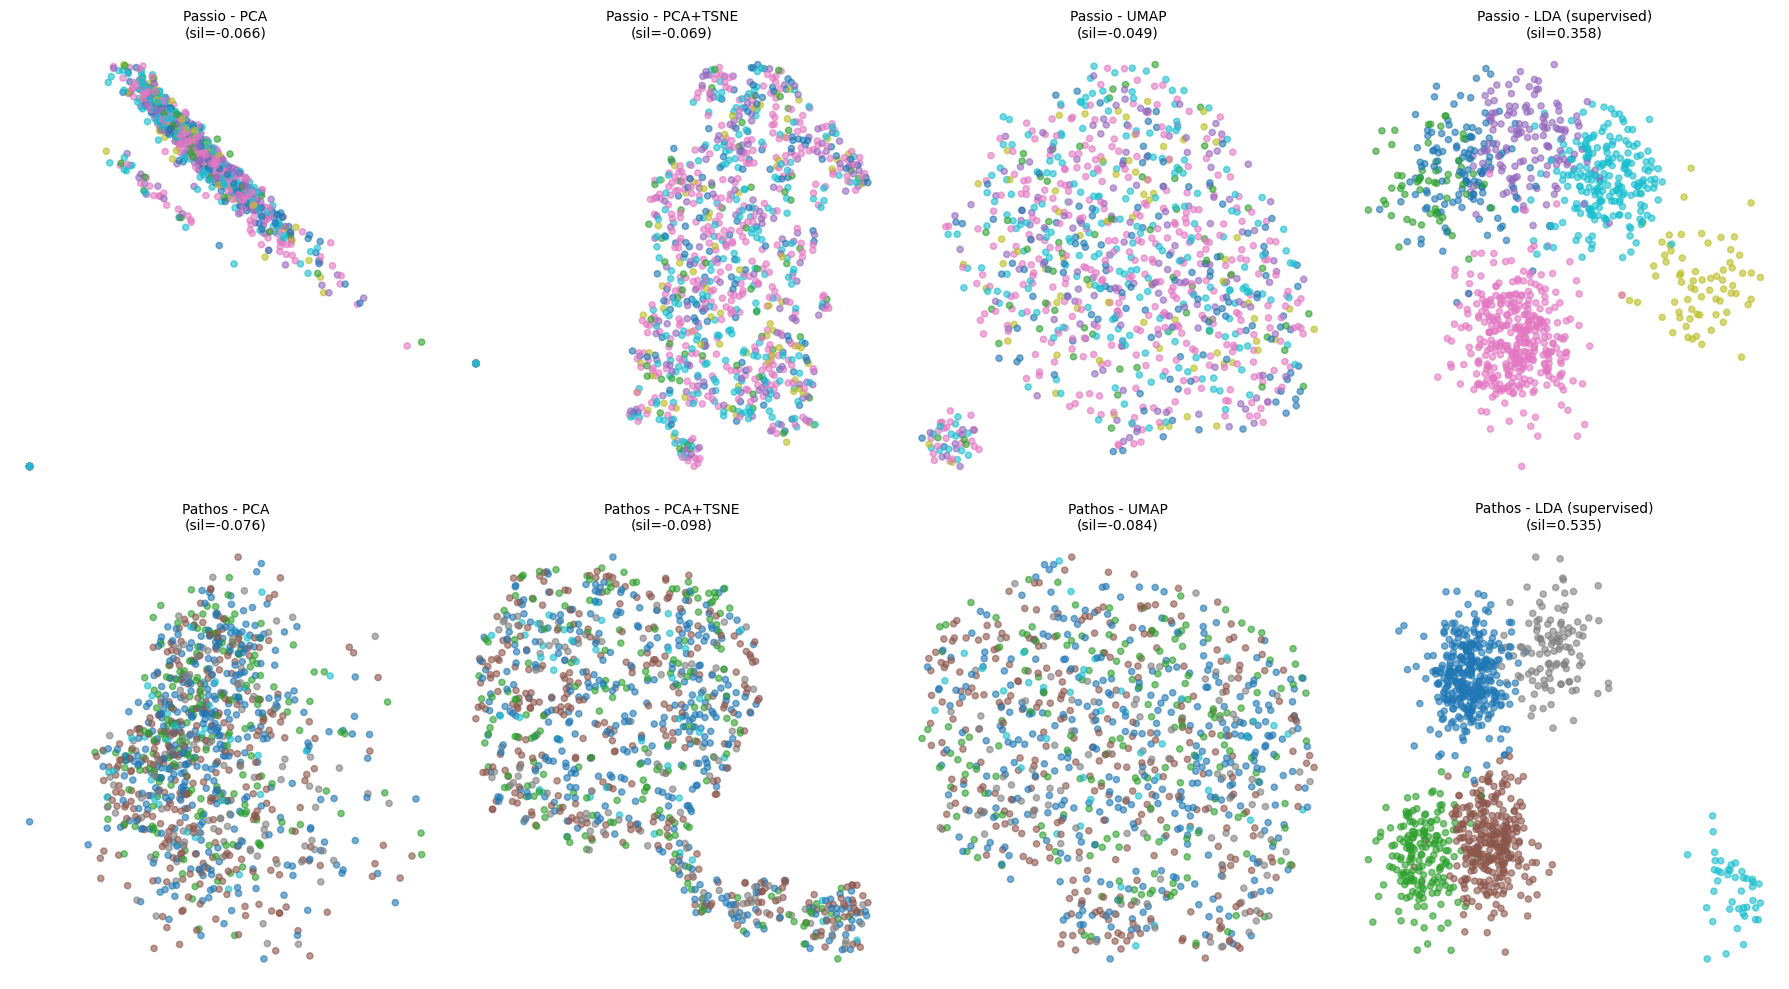


Key observation: LDA achieves clear separation while unsupervised methods show overlapping clusters.

=== Top 5 Discriminative Dimensions ===

PASSIO:
  Dim 723: 93.171
  Dim 182: 28.968
  Dim 664: 13.483
  Dim 212: 13.340
  Dim 529: 12.069

PATHOS:
  Dim 723: 29.343
  Dim 277: 10.953
  Dim 389: 9.871
  Dim 575: 9.292
  Dim 423: 9.073


In [7]:
# =============================================================================
# VISUALIZATION: Side-by-side comparison for Passio AND Pathos
# =============================================================================
fig, axes = plt.subplots(2, 4, figsize=(18, 10))

cmap = 'tab10'

# PASSIO ROW
axes[0, 0].scatter(X_pca_passio[:, 0], X_pca_passio[:, 1], c=y_passio, cmap=cmap, s=20, alpha=0.6)
axes[0, 0].set_title(f'Passio - PCA\n(sil={results_passio["PCA"]:.3f})', fontsize=10)
axes[0, 0].axis('off')

axes[0, 1].scatter(X_pca10tsne_passio[:, 0], X_pca10tsne_passio[:, 1], c=y_passio, cmap=cmap, s=20, alpha=0.6)
axes[0, 1].set_title(f'Passio - PCA+TSNE\n(sil={results_passio["PCA+TSNE(10)"]:.3f})', fontsize=10)
axes[0, 1].axis('off')

axes[0, 2].scatter(X_umap_passio[:, 0], X_umap_passio[:, 1], c=y_passio, cmap=cmap, s=20, alpha=0.6)
axes[0, 2].set_title(f'Passio - UMAP\n(sil={results_passio["UMAP(50,0.5)"]:.3f})', fontsize=10)
axes[0, 2].axis('off')

axes[0, 3].scatter(X_lda_passio[:, 0], X_lda_passio[:, 1], c=y_passio, cmap=cmap, s=20, alpha=0.6)
axes[0, 3].set_title(f'Passio - LDA (supervised)\n(sil={results_passio["LDA (supervised)"]:.3f})', fontsize=10)
axes[0, 3].axis('off')

# PATHOS ROW
axes[1, 0].scatter(X_pca_pathos[:, 0], X_pca_pathos[:, 1], c=y_pathos, cmap=cmap, s=20, alpha=0.6)
axes[1, 0].set_title(f'Pathos - PCA\n(sil={results_pathos["PCA"]:.3f})', fontsize=10)
axes[1, 0].axis('off')

axes[1, 1].scatter(X_pca10tsne_pathos[:, 0], X_pca10tsne_pathos[:, 1], c=y_pathos, cmap=cmap, s=20, alpha=0.6)
axes[1, 1].set_title(f'Pathos - PCA+TSNE\n(sil={results_pathos["PCA+TSNE(10)"]:.3f})', fontsize=10)
axes[1, 1].axis('off')

axes[1, 2].scatter(X_umap_pathos[:, 0], X_umap_pathos[:, 1], c=y_pathos, cmap=cmap, s=20, alpha=0.6)
axes[1, 2].set_title(f'Pathos - UMAP\n(sil={results_pathos["UMAP(50,0.5)"]:.3f})', fontsize=10)
axes[1, 2].axis('off')

axes[1, 3].scatter(X_lda_pathos[:, 0], X_lda_pathos[:, 1], c=y_pathos, cmap=cmap, s=20, alpha=0.6)
axes[1, 3].set_title(f'Pathos - LDA (supervised)\n(sil={results_pathos["LDA (supervised)"]:.3f})', fontsize=10)
axes[1, 3].axis('off')

plt.tight_layout()
plt.show()

print('\nKey observation: LDA achieves clear separation while unsupervised methods show overlapping clusters.')

# Feature importance
print('\n=== Top 5 Discriminative Dimensions ===')
print('\nPASSIO:')
top_dims_passio = lda_passio.get_top_dimensions(k=5)
importances_passio = lda_passio.get_feature_importances()
for idx in top_dims_passio:
    print(f'  Dim {idx:3d}: {importances_passio[idx]:.3f}')

print('\nPATHOS:')
top_dims_pathos = lda_pathos.get_top_dimensions(k=5)
importances_pathos = lda_pathos.get_feature_importances()
for idx in top_dims_pathos:
    print(f'  Dim {idx:3d}: {importances_pathos[idx]:.3f}')

In [8]:
from projections_helpers import (
         compute_century_trajectories_data,
         plot_3d_century_trajectories,
         create_label_palette
     )

In [13]:
# Prepare label names for plotting

from llmprompt_passio import LABEL_MAP as LABEL_MAP_PASSIO
from llmprompt_pathos import LABEL_MAP as LABEL_MAP_PATHOS



label_names_passio = {i: f"Sense {i}" for i in range(len(np.unique(y_passio)))}
label_names_pathos = {i: f"Sense {i}" for i in range(len(np.unique(y_pathos)))}

# Create color palettes
palette_passio = create_label_palette(len(np.unique(y_passio)))
palette_pathos = create_label_palette(len(np.unique(y_pathos)))

In [29]:
from importlib import reload
import projections_helpers
reload(projections_helpers)
from projections_helpers import (
         compute_century_trajectories_data,
         plot_3d_century_trajectories,
         create_label_palette
     )   #%%



In [30]:
trajectories_passio = compute_century_trajectories_data(
         df=passio_df,
         X=X_passio_clean,
         y=y_passio,
         lda_model=lda_passio,
         date_column='random_date',
         min_samples=5
     )     #%%

In [31]:
trajectories_passio

{0: {'centuries': [150,
   350,
   450,
   550,
   650,
   750,
   850,
   950,
   1050,
   1150,
   1250,
   1350,
   1450,
   1550,
   1650,
   1750],
  'x': [-2.348862648010254,
   -2.435131788253784,
   -2.386003017425537,
   -1.9926092624664307,
   -2.5486221313476562,
   -2.007181167602539,
   -2.656967878341675,
   -1.7355268001556396,
   -2.870253324508667,
   -2.4926981925964355,
   -2.652517795562744,
   -3.0183682441711426,
   -1.5607210397720337,
   -1.8538886308670044,
   -2.7474253177642822,
   -1.7411189079284668],
  'y': [1.458522081375122,
   1.4469302892684937,
   1.93027663230896,
   1.5051219463348389,
   1.8626044988632202,
   2.3055686950683594,
   2.403057813644409,
   2.0274245738983154,
   1.7571228742599487,
   1.5041805505752563,
   1.6062277555465698,
   1.216331958770752,
   1.8218666315078735,
   1.4255573749542236,
   1.8861769437789917,
   3.198728084564209],
  'z': [150,
   350,
   450,
   550,
   650,
   750,
   850,
   950,
   1050,
   1150,
   1250,


In [32]:
trajectories_pathos = compute_century_trajectories_data(
         df=pathos_df,
         X=X_pathos_clean,
         y=y_pathos,
         lda_model=lda_pathos,
         date_column='random_date',
         min_samples=5
     )     #%%

In [34]:
trajectories_pathos

{0: {'centuries': [-550,
   -450,
   -350,
   -250,
   -150,
   -50,
   50,
   150,
   250,
   350,
   450,
   550,
   650,
   750,
   850,
   950,
   1050,
   1150,
   1350],
  'x': [1.1191836595535278,
   0.4185863137245178,
   -0.7106183171272278,
   -1.4963711500167847,
   -0.9776114821434021,
   -0.7380293011665344,
   -0.6195849776268005,
   -1.1001436710357666,
   -1.127609372138977,
   -1.0175201892852783,
   -0.593234658241272,
   -1.0096030235290527,
   -1.0494225025177002,
   -0.898026704788208,
   -0.45695191621780396,
   -1.2569327354431152,
   -1.1188958883285522,
   -0.692704975605011,
   -0.7033658027648926],
  'y': [3.6216471195220947,
   2.7705509662628174,
   2.6302077770233154,
   2.428115129470825,
   3.417316198348999,
   2.99055814743042,
   2.878445863723755,
   2.5825142860412598,
   2.822220802307129,
   2.4609286785125732,
   2.7628419399261475,
   2.4747400283813477,
   2.597705841064453,
   2.8748273849487305,
   3.185959815979004,
   3.4308419227600098,
  

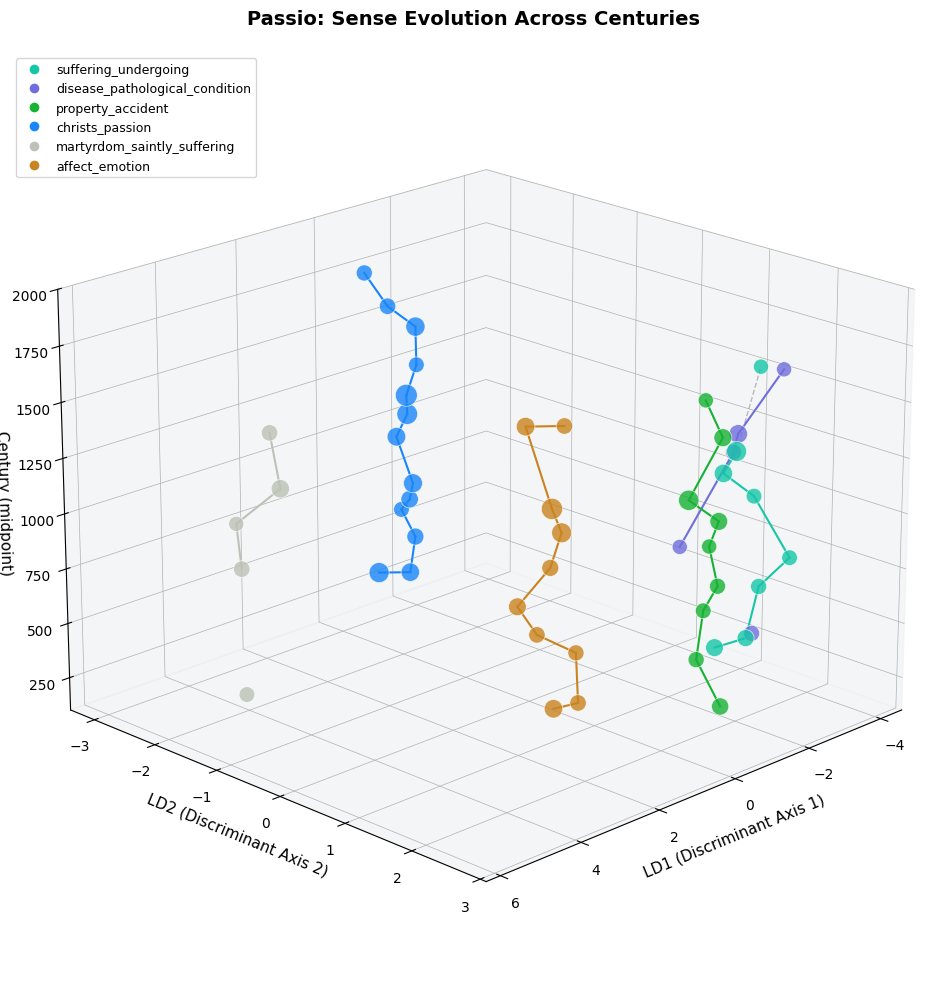

In [35]:
# Create palette and plot
palette_passio = create_label_palette(len(LABEL_MAP_PASSIO))
fig_passio = plot_3d_century_trajectories(
         trajectory_data=trajectories_passio,
         label_names=LABEL_MAP_PASSIO,
         palette=palette_passio,
         title="Passio: Sense Evolution Across Centuries",
         figsize=(14, 10),
         interpolate_gaps=True,
         max_gap_centuries=2
     )
plt.show()

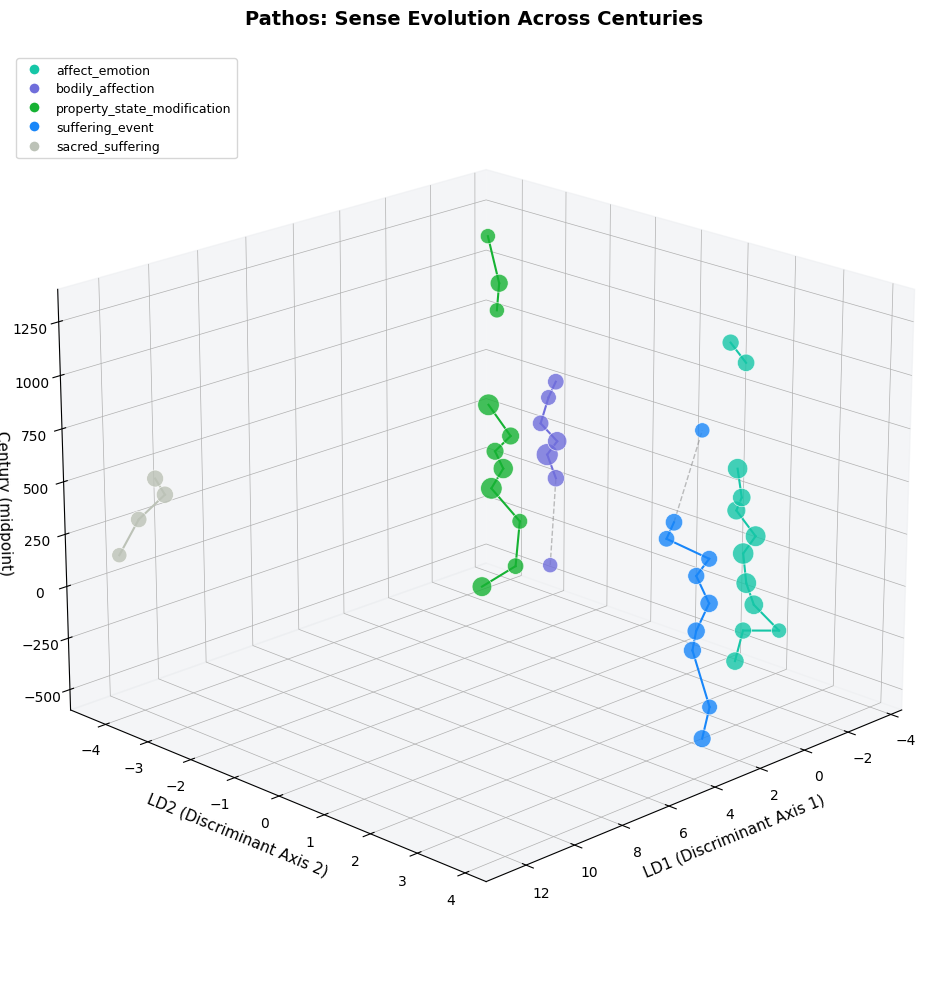

In [36]:
palette_pathos = create_label_palette(len(LABEL_MAP_PATHOS))
fig_pathos = plot_3d_century_trajectories(
         trajectory_data=trajectories_pathos,
         label_names=LABEL_MAP_PATHOS,
         palette=palette_pathos,
         title="Pathos: Sense Evolution Across Centuries",
         figsize=(14, 10),
         interpolate_gaps=True,
         max_gap_centuries=2
     )
plt.show()